# 22. A daily M4 forecasting project: development, cost and resume

**Objective and requirements.** Conduct a forecasting project from sample definition to delivery: audit real data, prepare temporal validation, run four selection procedures, measure coverage and cost, and resume execution through SQLite. We use daily M4 data, protocol A (14 steps at once), one seed and a `smoke` budget. Requires the AutoHybTS version accompanying this tutorial and the `notebook,stats,plot` extras; the first execution downloads metadata and training data.

The project uses **official training data only**. Its final block is reserved for internal evaluation; the official test is neither downloaded nor read. This stage establishes functionality and cost before scaling the study. Artifacts are generated in an execution-relative directory defined below.

In [1]:
import hashlib
import json
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.benchmarks import ablation_report, benchmark_cases, run_ablation
from autohybts.persistence.manifest import json_safe

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc4


## 1. Data and protocol

First freeze the reproducible decisions: sample size, sampling seed, model seeds, maximum history length and budget. The provider samples series with the declared seed; identifiers come from the data rather than manual selection. We retain up to 730 observations per series to control this stage's cost. The 14-step horizon and the MASE scaling period come from the daily M4 provider.

Variant A predicts the entire block from one origin. The search offers naive, seasonal naive and linear regression bases, with linear correctors over windows of seven out-of-sample residuals. MASE drives selection; MAE, RMSE and sMAPE are also recorded. Thresholds are fixed before internal evaluation: 5% median gain, 60% win rate, 5% variability and full coverage. The small `epsilon` constant stabilizes policy calculations.

The output directory identifies this execution. Use a different directory after changing data, code or configuration; the checkpoint checks compatibility before reusing results.

In [2]:
CONFIG = {
    "schema": "autohybts-ablation-config/1",
    "preset": "research",
    "dataset": "m4-daily",
    "n_series": 3,
    "sampling_seed": 0,
    "seeds": [0],
    "budget": "smoke",
    "outer_folds": 1,
    "development_only": True,
    "development_tail": 730,
    "space": {
        "variant": "A",
        "fold": "auto",
        "profile": "standard",
        "n_jobs": 1,
        "base_models": ["naive", "seasonal_naive", "linear"],
        "correctors": ["linear"],
        "residual_sources": ["historical_oof_1step"],
        "residual_windows": [7],
        "alphas": [1.0],
        "metrics": ["MASE", "MAE", "RMSE", "sMAPE"],
        "median_gain_threshold": 0.05,
        "win_rate_threshold": 0.6,
        "variability_threshold": 0.05,
        "min_coverage": 1.0,
        "epsilon": 1e-12,
    },
}

assert CONFIG["dataset"] == "m4-daily"
assert CONFIG["development_only"] is True
OUT = Path("artifacts") / "m4-development-project"
OUT.mkdir(parents=True, exist_ok=True)
CHECKPOINT = OUT / "state.sqlite"

policy_keys = [
    "median_gain_threshold",
    "win_rate_threshold",
    "variability_threshold",
    "min_coverage",
    "epsilon",
]
display(pd.Series({key: CONFIG["space"][key] for key in policy_keys}, name="threshold"))
print("Sample size:", CONFIG["n_series"], "seeds:", CONFIG["seeds"], "budget:", CONFIG["budget"])

median_gain_threshold    5.000000e-02
win_rate_threshold       6.000000e-01
variability_threshold    5.000000e-02
min_coverage             1.000000e+00
epsilon                  1.000000e-12
Name: threshold, dtype: float64

Sample size: 3 seeds: [0] budget: smoke


## 2. Causal exploration and audit

Before searching models, inspect the available history: length, finite values, timestamp ordering, duplicates and regularity. `development_only=True` loads official training data only and reserves its final block for internal evaluation. The calendar comes from the provider; regular indexing does not establish original dates.

Read the table before proceeding: `original_train_length` is the original length; other fields describe retained history and detected issues. A blocked status stops execution. Warnings require checking whether history supports the intended origins, without automatically imputing or excluding observations. The official test does not inform sample decisions.

In [3]:
cases = list(
    benchmark_cases(
        "m4",
        "daily",
        CONFIG["n_series"],
        CONFIG["sampling_seed"],
        development_only=True,
        development_tail=CONFIG["development_tail"],
    )
)
assert all(case.source["official_test_accessed"] is False for case in cases)
audit = pd.DataFrame(
    [
        {
            "series_id": case.series_id,
            "horizon": case.horizon,
            "seasonal_period": case.seasonal_period,
            "original_train_length": case.source["original_train_length"],
            **case.source["data_audit"],
        }
        for case in cases
    ]
)
display(audit)
assert audit["status"].isin(["READY", "READY_WITH_WARNINGS"]).all()

,series_id,horizon,seasonal_period,original_train_length,status,observations,missing,nonfinite,duplicate_timestamps,chronological,regular,start,end,constant
0,D2692,14,1,4197,READY,730,0,0,0,True,True,2010-09-26 00:00:00,2012-09-24 00:00:00,False
1,D2161,14,1,172,READY,172,0,0,0,True,True,2002-12-23 00:00:00,2003-06-12 00:00:00,False
2,D3594,14,1,4197,READY,730,0,0,0,True,True,2010-09-26 00:00:00,2012-09-24 00:00:00,False


## 3. Controls and proposed models

The comparison changes selection procedures while keeping data, horizon, metric and budget common:

| Procedure | Decision |
| --- | --- |
| `lowest_error` | Choose the finalist with the lowest mean error on `V_select`. |
| `incremental` | Accept additional complexity only when it passes the incremental policy. |
| `incremental_simple` | Apply that policy to structures with at most two fitted models. |
| `guarded_nested` | Add nested validation; keep the standalone reference when the procedure does not outperform it. |

The standalone reference has the lowest standalone error on `V_select`; naive and seasonal naive errors are also recorded. These are not four independent searches: some procedures share work.

Before execution, `fit` prepares the temporal plan without running the search. `V_search` tunes candidates and `V_select` selects them; the final block stays outside these decisions. `fold="auto"` adapts the number of origins to history length. The first table shows available origins in the main plan and earliest inner fold. The second exposes split boundaries. Inspect warnings, especially when short histories reduce the number of origins.

In [4]:
plans, split_tables, preflight_messages = [], {}, []
for case in cases:
    settings = {
        **CONFIG["space"],
        "fh": case.horizon,
        "seasonal_period": case.seasonal_period,
        "budget": CONFIG["budget"],
        "session_id": CONFIG["seeds"][0],
    }
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        exp = AutoHybridExperiment(**settings, test_size=case.test_size).fit(case.values)
        inner = AutoHybridExperiment(**settings, test_size=0).fit(
            case.values.iloc[: -case.test_size - CONFIG["outer_folds"] * case.horizon]
        )
    assert exp.history_.end < case.values.index[-case.test_size]
    split_tables[case.series_id] = exp.splits
    plans.append(
        {
            "series_id": case.series_id,
            "folds_per_layer": exp.fold_,
            "earliest_inner_folds": inner.fold_,
            "horizon": case.horizon,
        }
    )
    preflight_messages.extend(str(item.message) for item in caught)
display(pd.DataFrame(plans))
display(pd.concat(split_tables, names=["series_id"]))
for message in sorted(set(preflight_messages)):
    print("WARNING:", message)

,series_id,folds_per_layer,earliest_inner_folds,horizon
0,D2692,7,7,14
1,D2161,4,4,14
2,D3594,7,7,14


layer train_start     origin first_target last_target  n_train  horizon
series_id fold_id                                                                           
D2692     search-0  search  2010-09-26 2012-02-27   2012-02-28  2012-03-12      520       14
          search-1  search  2010-09-26 2012-03-12   2012-03-13  2012-03-26      534       14
          search-2  search  2010-09-26 2012-03-26   2012-03-27  2012-04-09      548       14
          search-3  search  2010-09-26 2012-04-09   2012-04-10  2012-04-23      562       14
          search-4  search  2010-09-26 2012-04-23   2012-04-24  2012-05-07      576       14
          search-5  search  2010-09-26 2012-05-07   2012-05-08  2012-05-21      590       14
          search-6  search  2010-09-26 2012-05-21   2012-05-22  2012-06-04      604       14
          select-0  select  2010-09-26 2012-06-04   2012-06-05  2012-06-18      618       14
          select-1  select  2010-09-26 2012-06-18   2012-06-19  2012-07-02      632       14
          select-2  select  2010-09-26 2012-07-02   2012-07-03  2012-07-16      646       14
          select-3  select  2010-09-26 2012-07-16   2012-07-17  2012-07-30      660       14
          select-4  select  2010-09-26 2012-07-30   2012-07-31  2012-08-13      674       14
          select-5  select  2010-09-26 2012-08-13   2012-08-14  2012-08-27      688       14
          select-6  select  2010-09-26 2012-08-27   2012-08-28  2012-09-10      702       14
D2161     search-0  search  2002-12-23 2003-02-06   2003-02-07  2003-02-20       46       14
          search-1  search  2002-12-23 2003-02-20   2003-02-21  2003-03-06       60       14
          search-2  search  2002-12-23 2003-03-06   2003-03-07  2003-03-20       74       14
          search-3  search  2002-12-23 2003-03-20   2003-03-21  2003-04-03       88       14
          select-0  select  2002-12-23 2003-04-03   2003-04-04  2003-04-17      102       14
          select-1  select  2002-12-23 2003-04-17   2003-04-18  2003-05-01      116       14
          select-2  select  2002-12-23 2003-05-01   2003-05-02  2003-05-15      130       14
          select-3  select  2002-12-23 2003-05-15   2003-05-16  2003-05-29      144       14
D3594     search-0  search  2010-09-26 2012-02-27   2012-02-28  2012-03-12      520       14
          search-1  search  2010-09-26 2012-03-12   2012-03-13  2012-03-26      534       14
          search-2  search  2010-09-26 2012-03-26   2012-03-27  2012-04-09      548       14
          search-3  search  2010-09-26 2012-04-09   2012-04-10  2012-04-23      562       14
          search-4  search  2010-09-26 2012-04-23   2012-04-24  2012-05-07      576       14
          search-5  search  2010-09-26 2012-05-07   2012-05-08  2012-05-21      590       14
          search-6  search  2010-09-26 2012-05-21   2012-05-22  2012-06-04      604       14
          select-0  select  2010-09-26 2012-06-04   2012-06-05  2012-06-18      618       14
          select-1  select  2010-09-26 2012-06-18   2012-06-19  2012-07-02      632       14
          select-2  select  2010-09-26 2012-07-02   2012-07-03  2012-07-16      646       14
          select-3  select  2010-09-26 2012-07-16   2012-07-17  2012-07-30      660       14
          select-4  select  2010-09-26 2012-07-30   2012-07-31  2012-08-13      674       14
          select-5  select  2010-09-26 2012-08-13   2012-08-14  2012-08-27      688       14
          select-6  select  2010-09-26 2012-08-27   2012-08-28  2012-09-10      702       14

## 4. Search and selection

`run_ablation` executes the procedures on common series × seed units. The final development block only evaluates the choice made before it. The nested guard uses earlier folds to decide. The `smoke` budget is a small execution of the real workflow; its accuracy does not represent a broad search.

The database records completed cases. When a compatible checkpoint exists, `resume=True` reuses successes. `on_error="record"` preserves failures; coverage distinguishes missing results from poor performance. `n_jobs=1` and a single BLAS thread reduce concurrency to make cost easier to interpret.

We expect one completed case per series × seed and four rows per case. Warnings remain visible, and the checks below stop the workflow if an expected result is missing.

In [5]:
arguments = dict(
    seeds=CONFIG["seeds"],
    budget=CONFIG["budget"],
    space=CONFIG["space"],
    outer_folds=CONFIG["outer_folds"],
    checkpoint=CHECKPOINT,
    configuration=CONFIG,
    on_error="record",
)
started = time.perf_counter()
with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
    warnings.simplefilter("always")
    table = run_ablation(cases, **arguments, resume=CHECKPOINT.exists(), progress=print)
warning_counts = Counter(str(item.message) for item in caught)
coverage = table.attrs["coverage"]
print("Invocation seconds:", round(time.perf_counter() - started, 2))
print(
    {
        key: coverage[key]
        for key in (
            "n_planned_cases",
            "n_succeeded_cases",
            "n_failed_cases",
            "n_skipped_cases",
            "n_result_rows",
        )
    }
)
display(pd.DataFrame(coverage["procedures"]).T)
for message, count in warning_counts.items():
    print(f"WARNING ({count}): {message}")
assert coverage["n_succeeded_cases"] == len(cases) * len(CONFIG["seeds"])
assert coverage["n_result_rows"] == 4 * len(cases) * len(CONFIG["seeds"])

Invocation seconds: 0.11
{'n_planned_cases': 3, 'n_succeeded_cases': 3, 'n_failed_cases': 0, 'n_skipped_cases': 0, 'n_result_rows': 12}


,n_planned,n_succeeded,n_metric_valid,n_paired,metric_coverage,paired_coverage
lowest_error,3.0,3.0,3.0,3.0,1.0,1.0
incremental,3.0,3.0,3.0,3.0,1.0,1.0
incremental_simple,3.0,3.0,3.0,3.0,1.0,1.0
guarded_nested,3.0,3.0,3.0,3.0,1.0,1.0


## 5. Results and plots

The first table shows each procedure's champion and errors: `validation_score` on `V_select`, `internal_MASE` on the reserved block and `reference_internal_MASE` for the standalone reference on that same block. Lower MASE is better; positive `gain_vs_base` means reduced error against the reference. Coverage reports availability of validation units. The CSV's `test_score` is the API's generic field name; in this configuration it refers exclusively to the internal official-training block.

The next table reports case status, attempts and seconds. The procedure summary presents paired coverage and effort per procedure: `candidates` counts candidates, `units` counts evaluation units and `mean_seconds` summarizes search cost. Paired coverage of 1 means every row has the reference needed for comparison.

The plots relate retained history length to observed cost. Do not sum the four procedures' costs: some searches share work. Case totals count executed work once, including additional stages. A resumed invocation can be fast while historical training cost remains recorded.

Forecasting metrics are available in `table` and the exported CSV. This reading focuses on project sizing; a small sample and one seed do not establish procedure superiority.

,series_id,procedure,champion,validation_score,internal_MASE,reference_internal_MASE,gain_vs_base,coverage
0,D2692,lowest_error,linear,2.8027,2.7242,2.7242,0.0000,1.0
1,D2692,incremental,naive,2.8875,3.0579,2.7242,-0.1225,1.0
2,D2692,incremental_simple,naive,2.8875,3.0579,2.7242,-0.1225,1.0
3,D2692,guarded_nested,linear,2.8027,2.7242,2.7242,0.0000,1.0
4,D2161,lowest_error,naive-linear,2.0855,2.4264,2.5909,0.0635,1.0
5,D2161,incremental,naive-linear,2.0855,2.4264,2.5909,0.0635,1.0
6,D2161,incremental_simple,naive-linear,2.0855,2.4264,2.5909,0.0635,1.0
7,D2161,guarded_nested,naive,2.2141,2.5909,2.5909,0.0000,1.0
8,D3594,lowest_error,naive,2.2427,0.7914,0.7914,0.0000,1.0
9,D3594,incremental,naive,2.2427,0.7914,0.7914,0.0000,1.0


,series_id,seed,status,attempts,seconds
0,D2692,0,SUCCEEDED,1,39.398
1,D2161,0,SUCCEEDED,1,1.627
2,D3594,0,SUCCEEDED,1,84.985


Unique case seconds: 126.01


,n_rows,n_paired,paired_coverage,mean_seconds,candidates,units
procedure,,,,,,
lowest_error,3,3,1.0,19.532,10.000,90.0
incremental,3,3,1.0,19.532,10.000,90.0
incremental_simple,3,3,1.0,2.122,6.000,54.0
guarded_nested,3,3,1.0,39.781,19.333,176.0


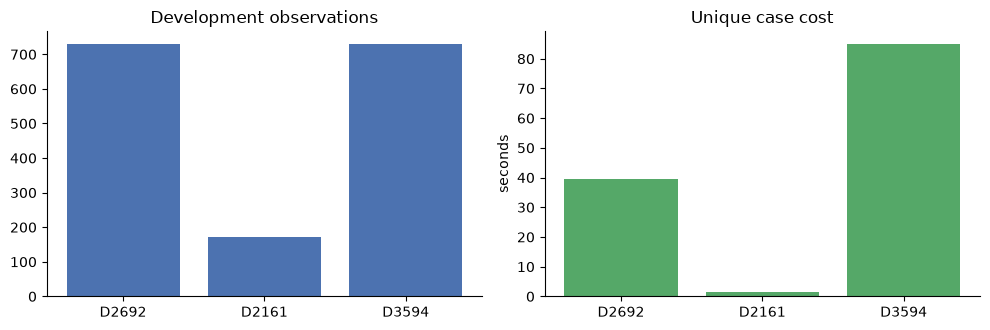

In [6]:
scores = table[
    [
        "series_id",
        "procedure",
        "champion",
        "validation_score",
        "test_score",
        "best_base_test",
        "gain_vs_base",
        "coverage",
    ]
].rename(columns={"test_score": "internal_MASE", "best_base_test": "reference_internal_MASE"})
display(scores.round(4))

case_cost = pd.DataFrame(
    [
        {
            "series_id": state["series_id"],
            "seed": state["seed"],
            "status": state["status"],
            "attempts": len(state["history"]),
            "seconds": sum(attempt.get("seconds") or 0 for attempt in state["history"]),
        }
        for state in table.attrs["cases"]
    ]
)
assert abs(case_cost["seconds"].sum() - coverage["known_seconds_total"]) < 1e-6
display(case_cost.round(3))
print("Unique case seconds:", round(coverage["known_seconds_total"], 2))
columns = ["n_rows", "n_paired", "paired_coverage", "mean_seconds", "candidates", "units"]
display(ablation_report(table)[columns].round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar(audit["series_id"], audit["observations"], color="#4C72B0")
axes[0].set_title("Development observations")
axes[1].bar(case_cost["series_id"], case_cost["seconds"], color="#55A868")
axes[1].set_title("Unique case cost")
axes[1].set_ylabel("seconds")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "pilot_cost.png", dpi=120, bbox_inches="tight")
fig.savefig(OUT / "pilot_cost.svg", bbox_inches="tight")
plt.show()

## 6. Diagnostics and limits

Resume is part of the project workflow: interruptions should not require repeating completed cases. We invoke the same execution again and check two properties: identical CSV content and no increase in attempts. This checks checkpoint reuse; it is not another training-cost measurement.

Truncated histories, few series, one seed and a reduced budget limit generalization. Available origins can differ between series. Timings depend on hardware, initialization and caches. Before scaling up, fix short-history rules and increase sample size and budget within available resources.

In [7]:
before_csv = table.to_csv(index=False).encode("utf-8")
before_attempts = coverage["n_attempts"]
with threadpool_limits(limits=1):
    reused = run_ablation(cases, **arguments, resume=True)
assert reused.to_csv(index=False).encode("utf-8") == before_csv
assert reused.attrs["coverage"]["n_attempts"] == before_attempts
print(
    {
        "csv_identical": True,
        "new_attempts": 0,
        "reused_cases": reused.attrs["coverage"]["n_succeeded_cases"],
    }
)

{'csv_identical': True, 'new_attempts': 0, 'reused_cases': 3}


## 7. Internal evaluation and delivery

The reserved block was already evaluated in `run_ablation`, after selection. This stage exports existing results without reading that block again. The official test remains outside this project; evaluate it only after freezing the expanded study design.

The CSV contains metrics per series, seed and procedure. The resolved protocol records configuration, coverage, temporal plans and warnings. The manifest identifies environment and sources and hashes the files. SQLite supports case resume. Figures and split tables accompany delivery so readers can review both results and how they were obtained.

In [8]:
table.to_csv(OUT / "results.csv", index=False)
audit.to_csv(OUT / "data_audit.csv", index=False)
for series_id, splits in split_tables.items():
    splits.reset_index().to_csv(OUT / f"{series_id}-splits.csv", index=False)
protocol = {
    **table.attrs["protocol"],
    "resolved_cases": table.attrs["cases"],
    "coverage": coverage,
    "temporal_preflight": plans,
    "preflight_warnings": sorted(set(preflight_messages)),
    "execution_warnings": dict(warning_counts),
    "threadpool_limit": 1,
    "official_test_accessed": False,
}
(OUT / "resolved_protocol.json").write_text(
    json.dumps(json_safe(protocol), indent=2, ensure_ascii=False, allow_nan=False),
    encoding="utf-8",
)
files = [
    "results.csv",
    "data_audit.csv",
    "resolved_protocol.json",
    "state.sqlite",
    "pilot_cost.png",
    "pilot_cost.svg",
    *[f"{case.series_id}-splits.csv" for case in cases],
]
manifest = {
    "study_id": protocol["study_id"],
    "source_fingerprint": protocol["source_fingerprint"],
    "environment": protocol["environment"],
    "resume_csv_identical": True,
    "sha256": {name: hashlib.sha256((OUT / name).read_bytes()).hexdigest() for name in files},
}
(OUT / "manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Output:", OUT.as_posix())
print(sorted([*files, "manifest.json"]))

Output: artifacts/m4-development-project
['D2161-splits.csv', 'D2692-splits.csv', 'D3594-splits.csv', 'data_audit.csv', 'manifest.json', 'pilot_cost.png', 'pilot_cost.svg', 'resolved_protocol.json', 'results.csv', 'state.sqlite']


## 8. Reading

**Recorded execution.** 3 completed cases, 12 rows and 0 failures. Executed work totaled 126.0 seconds. Main plans allowed 4, 7 origins per layer depending on available history; reduced-origin warnings remain visible. Resume preserved CSV content without new attempts. These timings describe this execution.

- **Functionality.** Compare planned and completed cases and check four rows per case. Resolve failures or incomplete coverage before scaling execution.
- **Data and validation.** The audit and temporal plans expose retained history and available origins. Short-history warnings should inform an explicit rule for the next stage.
- **Cost.** Use case totals for resource planning. Procedure costs include shared work and must not be summed as independent executions.
- **Continuity.** The second invocation should show reused cases, no new attempts and identical CSV content.
- **Next decision.** Fix sample size, budget, short-history handling and comparators before the expanded study. This stage cannot support a generalizable accuracy ranking.